# 08 · Định mức đúng/trễ và độ đo trung tâm (Chương 3)

## 1. Mục tiêu và buổi học áp dụng

Trả lời **câu hỏi quản trị 2** ở mức chi tiết (*trễ ở trạng thái nào, vai trò nào?*) và tạo **danh sách ưu tiên cải tiến có bằng chứng** cho Chương 4. Áp dụng **Buổi 3 — event log, định mức đúng/trễ, DFG và độ đo trung tâm** (degree, betweenness, closeness, eigenvector, PageRank).

## 2. Đầu vào

Run `outputs/process/<run>` (bước B: `b_norms/`), loader kiểm fingerprint.

In [1]:
# Mở run giai đoạn 2 đã kiểm fingerprint. Không cần biến môi trường: nếu không chỉ định, tự chọn run
# hoàn tất mới nhất khớp configs/process.yaml hiện tại (bộ chạy `jira-ad notebooks` đặt JIRA_AD_PROCESS_RUN_DIR).
import pandas as pd
from IPython.display import Markdown, display

from jira_ad import process_plots as pp
from jira_ad.process_analysis import fmt, open_process_run

pd.options.display.float_format = "{:.3f}".format
pd.options.display.max_colwidth = 100
run = open_process_run()
print(run.header())

run: outputs/process/20261026T025412Z-399b0a40
chọn run: biến môi trường JIRA_AD_PROCESS_RUN_DIR
config: configs/process.yaml
config_hash: 399b0a40534a3d08466aaaf32175a68cb6d59cf4d90af65301ebb04c5e572a22
code.sha256: ed83115da72a96af6ecac17610d370d96a617635e4abc0c807ee7459ba84e9b6
tạo lúc (UTC): 2026-10-26T02:54:12.298067+00:00
số artifact đã kiểm sha256: 93


In [2]:
cfg = run.manifest["config"]
display(pd.Series({"phân vị định mức": cfg["norms"]["percentile"],
                   "số lượt tối thiểu": cfg["norms"]["min_visits"],
                   "SLA cấu hình": cfg["norms"]["explicit_days"] or "(không có)",
                   "PageRank d": cfg["centrality"]["pagerank_alpha"],
                   "số ca train (DFG activity)": len(run.csv("b_norms/train_ids.csv"))},
                  name="giá trị").to_frame())

,giá trị
phân vị định mức,0.750
số lượt tối thiểu,10
SLA cấu hình,(không có)
PageRank d,0.850
số ca train (DFG activity),97


## 3. Dữ liệu và giả định

- **Công ty không có SLA chính thức** (Quyết định 3): định mức là **phân vị 0,75 của dwell lịch sử** theo trạng thái, đo bằng ngày làm việc, trên cả 161 ca (Ruling 69). Theo cấu tạo, khoảng 25% lượt của mỗi trạng thái "trễ"; vì vậy so sánh giữa trạng thái dựa vào **số ngày vượt định mức**, không dựa vào tỉ lệ trễ (Ruling 79).
- Trạng thái có < 10 lượt không có định mức (Ruling 78).
- Trễ theo vai trò gán cho **vai trò chuyển ca ra khỏi trạng thái**; `bot`/`unknown`/thiếu role báo riêng. Đây là mức vai trò, không đánh giá cá nhân.
- DFG trạng thái dùng cả 161 ca (mô tả); DFG activity chỉ dùng **97 ca train** của split V1 (mô hình có học).

## 4. Kết quả

### 4.1 Định mức theo trạng thái

In [3]:
display(run.csv("b_norms/norms.csv"))

,state,norm_days,source,n,median_days
0,DONE,NaN,quá_ít_lượt,4,0.003
1,INVESTIGATED,2.186,p75_lịch_sử,114,0.163
2,In Progress,3.028,p75_lịch_sử,99,0.794
3,In Test,9.812,p75_lịch_sử,91,3.025
4,Inbox,1.144,p75_lịch_sử,18,0.001
5,OPEN,NaN,quá_ít_lượt,1,0.000
6,Rejected,NaN,quá_ít_lượt,5,0.000
7,To Do,7.755,p75_lịch_sử,106,0.003
8,To Investigate,27.860,p75_lịch_sử,114,10.876
9,Triage,NaN,quá_ít_lượt,1,1.054


### 4.2 Trễ theo trạng thái

,state,norm_days,n_visits,n_judged,n_late,late_rate,excess_days,median_dwell_days,share_of_excess
0,To Do,7.755,106,106,27,0.255,1159.346,0.003,0.476
1,To Investigate,27.860,114,114,29,0.254,510.578,10.876,0.210
2,In Test,9.812,91,91,23,0.253,295.277,3.025,0.121
3,INVESTIGATED,2.186,114,114,29,0.254,188.585,0.163,0.077
4,__CREATED__,3.958,161,161,40,0.248,177.588,1.952,0.073
5,In Progress,3.028,99,99,25,0.253,95.602,0.794,0.039
6,Inbox,1.144,18,18,5,0.278,7.982,0.001,0.003
7,DONE,NaN,4,0,0,NaN,0.000,0.003,0.000
8,OPEN,NaN,1,0,0,NaN,0.000,0.000,0.000
9,Rejected,NaN,5,0,0,NaN,0.000,0.000,0.000


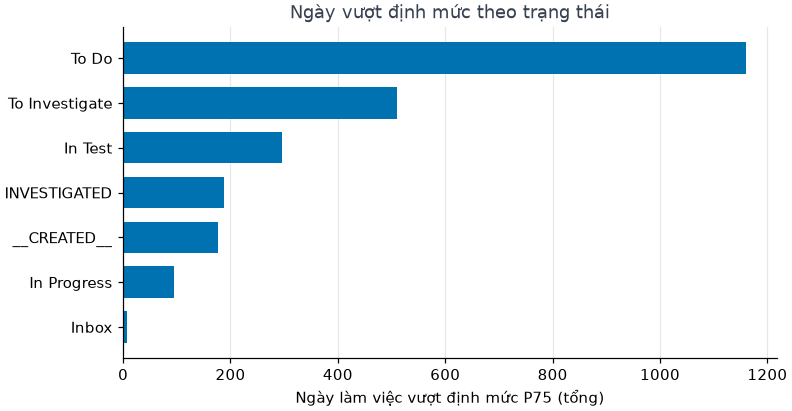

In [4]:
by_state = run.csv("b_norms/late_by_state.csv")
display(by_state)
_ = run.show(pp.plot_excess_days(by_state, key="state", title="Ngày vượt định mức theo trạng thái"))

### 4.3 Trễ theo vai trò chuyển ra

,role,is_human,n_exits,n_judged,n_late,late_rate,excess_days,median_dwell_days
0,PO,True,390,383,94,0.245,1298.098,1.173
1,Eng,True,136,133,29,0.218,222.713,0.001
2,SQA,True,55,55,18,0.327,171.288,3.307
3,RTE,True,5,5,0,0.000,0.000,0.000
4,Software Architect,True,1,1,0,0.000,0.000,1.910
5,unknown,False,127,126,37,0.294,742.860,7.760


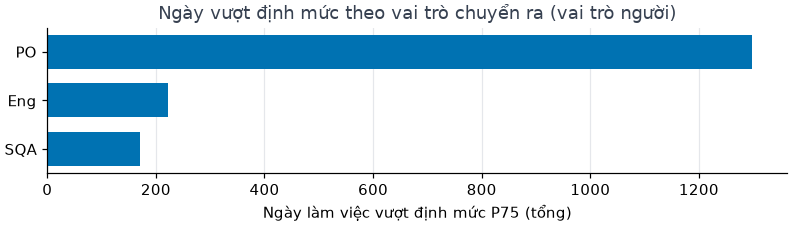

In [5]:
by_role = run.csv("b_norms/late_by_role.csv")
display(by_role)
_ = run.show(pp.plot_excess_days(by_role[by_role.is_human], key="role",
                                 title="Ngày vượt định mức theo vai trò chuyển ra (vai trò người)"))

### 4.4 Trễ theo ca và các lần trễ lớn nhất

In [6]:
by_case = run.csv("b_norms/late_by_case.csv")
display(pd.Series({"ca có ≥ 1 lượt trễ": int((by_case.n_late > 0).sum()),
                   "ca có CT vượt P75 của nhánh": int(by_case.ct_late.sum()),
                   "tổng số ca": len(by_case)}, name="số ca").to_frame())
display(run.csv("b_norms/top_late.csv"))

,số ca
ca có ≥ 1 lượt trễ,99
ca có CT vượt P75 của nhánh,41
tổng số ca,161


,case_id,terminal_status,state,visit_index,dwell_days,norm_days,excess_days,exit_role
0,bug:TI-5200,Rejected,To Do,5,149.946,7.755,142.191,PO
1,bug:TI-5378,Rejected,To Do,5,144.923,7.755,137.168,PO
2,bug:TI-4966,Rejected,To Do,1,144.032,7.755,136.277,PO
3,bug:TI-4751,DONE,To Do,1,135.086,7.755,127.330,PO
4,bug:TI-4683,Rejected,To Do,3,120.008,7.755,112.252,PO
5,bug:TI-5442,DONE,To Do,3,89.770,7.755,82.014,unknown
6,bug:TI-5269,DONE,To Do,1,83.796,7.755,76.041,unknown
7,bug:TI-4584,DONE,INVESTIGATED,2,65.172,2.186,62.986,PO
8,bug:TI-4967,DONE,To Do,3,68.018,7.755,60.262,unknown
9,bug:TI-4723,DONE,To Investigate,3,84.877,27.860,57.017,PO


### 4.5 DFG trạng thái và độ đo trung tâm

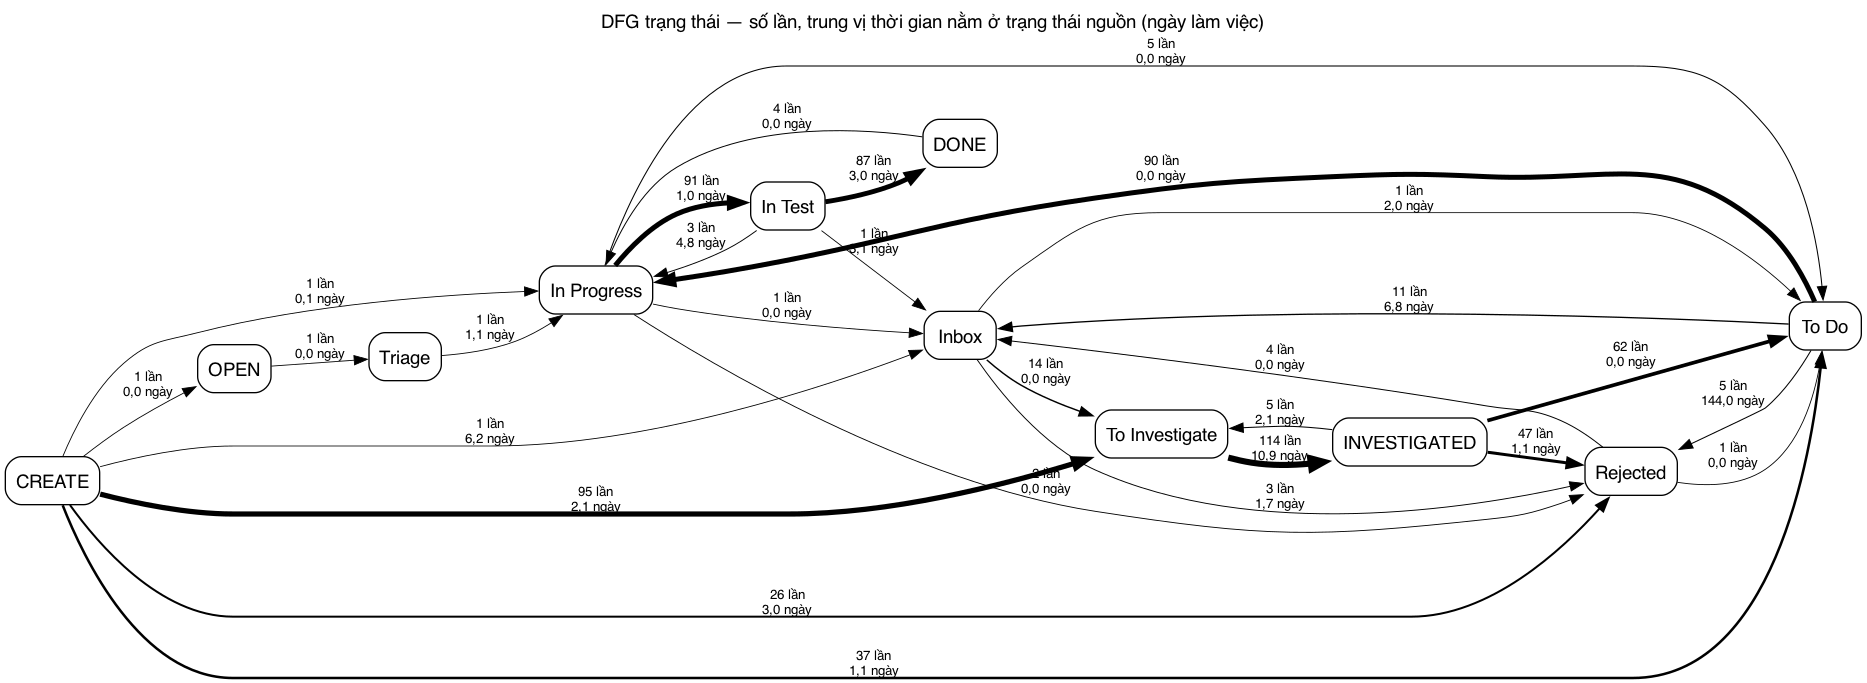

,node,in_degree,out_degree,in_strength,out_strength,betweenness,closeness_undirected,eigenvector_undirected,pagerank
0,CREATE,0,6,0,161,0.000,0.714,0.365,0.014
1,DONE,1,1,87,4,0.000,0.476,0.100,0.180
2,INVESTIGATED,1,3,114,114,0.067,0.476,0.503,0.068
3,In Progress,5,4,99,99,0.367,0.769,0.312,0.245
4,In Test,1,3,91,91,0.100,0.526,0.203,0.205
5,Inbox,5,3,18,18,0.167,0.714,0.075,0.061
6,OPEN,1,1,1,1,0.011,0.476,0.002,0.014
7,Rejected,5,2,83,5,0.011,0.667,0.195,0.055
8,To Do,5,3,106,106,0.144,0.667,0.406,0.070
9,To Investigate,3,1,114,114,0.100,0.526,0.507,0.063


In [7]:
from IPython.display import Image
display(Image(filename=str(run.path("b_norms/status_dfg.png"))))
display(run.csv("b_norms/centrality_status.csv"))

In [8]:
activity = run.csv("b_norms/centrality_activity.csv")
display(activity.sort_values("betweenness", ascending=False).head(12))

,node,in_degree,out_degree,in_strength,out_strength,betweenness,closeness_undirected,eigenvector_undirected,pagerank
11,EDIT_DESCRIPTION,24,28,215,215,0.231,0.774,0.439,0.072
4,ADD_ISSUE_LINK,21,25,214,214,0.180,0.750,0.586,0.076
17,REMOVE_ASSIGNEE,9,16,71,71,0.099,0.632,0.180,0.042
12,EDIT_ISSUEPARENTASSOCIATION,22,6,76,76,0.077,0.658,0.105,0.040
3,ADD_FIX_VERSION,17,19,58,58,0.070,0.676,0.116,0.035
34,UPDATE_BACKLOG_CLASSIFICATION,11,15,79,79,0.058,0.649,0.196,0.038
33,UPDATE_ASSIGNEE,13,19,50,50,0.054,0.658,0.104,0.036
0,ADD_ASSIGNEE,16,15,49,49,0.049,0.649,0.085,0.031
30,STATUS_To Do,21,10,62,62,0.045,0.667,0.141,0.042
15,LINK_COMMIT,15,13,169,169,0.038,0.632,0.139,0.049


### 4.6 Centrality × độ trễ và danh sách ưu tiên cải tiến

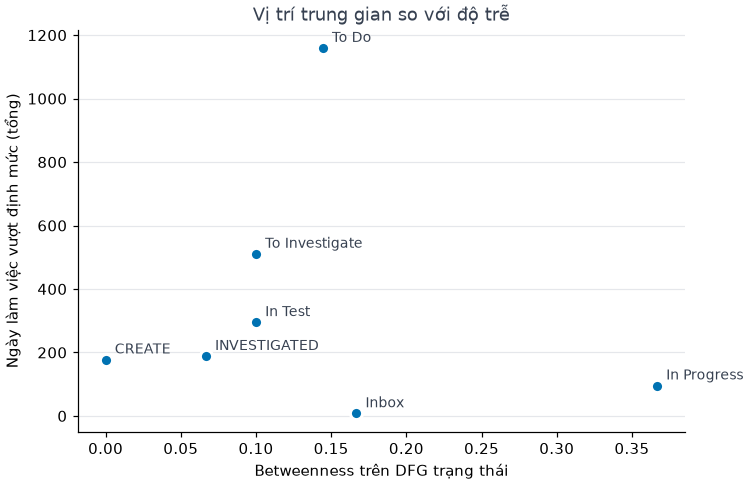

,rank,state,excess_days,share_of_excess,n_late,late_rate,norm_days,median_dwell_days,betweenness,pagerank,gate_role,gate_share,example_cases
0,1,To Do,1159.346,0.476,27,0.255,7.755,0.003,0.144,0.070,PO,0.755,"bug:TI-5200, bug:TI-5378, bug:TI-4966"
1,2,To Investigate,510.578,0.210,29,0.254,27.860,10.876,0.100,0.063,PO,0.912,"bug:TI-4723, bug:TI-4740, bug:TI-4683"
2,3,In Test,295.277,0.121,23,0.253,9.812,3.025,0.100,0.205,Eng,0.495,"bug:TI-4820, bug:TI-4584, bug:TI-5444"
3,4,INVESTIGATED,188.585,0.077,29,0.254,2.186,0.163,0.067,0.068,PO,0.202,"bug:TI-4584, bug:TI-5153, bug:TI-4617"
4,5,__CREATED__,177.588,0.073,40,0.248,3.958,1.952,0.000,0.014,NaN,NaN,"bug:TI-4820, bug:TI-4616, bug:TI-4649"
5,6,In Progress,95.602,0.039,25,0.253,3.028,0.794,0.367,0.245,PO,0.384,"bug:TI-5269, bug:TI-5041, bug:TI-5564"
6,7,Inbox,7.982,0.003,5,0.278,1.144,0.001,0.167,0.061,PO,0.722,"bug:TI-4671, bug:TI-4748, bug:TI-4686"


In [9]:
joined = run.csv("b_norms/centrality_vs_delay.csv")
_ = run.show(pp.plot_centrality_vs_delay(joined))
display(run.csv("b_norms/priorities.csv"))

## 5. Quá trình nghiên cứu

- **Lỗi DFG activity không trọng số (Ruling 80).** Bản đầu tiên tính centrality của DFG activity với thuộc tính cạnh `count`, nhưng `graph.build_dfg` của giai đoạn 1 lưu số lần chuyển ở thuộc tính `weight`. NetworkX coi thuộc tính thiếu là trọng số 1, nên strength, PageRank và eigenvector bị tính **như đồ thị không trọng số** mà không báo lỗi. Lỗi được phát hiện khi **kiểm chéo độc lập** so in-strength từng nút với `graph.graphml` của run V1 (lệch ở `ADD_EPIC_LINK`, `UPDATE_RANK`, `ADD_ASSIGNEE`). Cách sửa theo TDD: viết test tái hiện (`test_activity_dfg_centrality_is_weighted_by_transition_counts`, RED) → `activity_dfg_train` gắn `count = weight` cho mọi cạnh → GREEN; kiểm chéo lại khớp từng nút. Hai run mang lỗi đã được người dùng cho phép xóa; manifest nay ghi `code.sha256` để phân biệt run cùng cấu hình khác mã.
- **Quy ước trung tâm** (Ruling 77): betweenness có hướng không trọng số ("số lần" là tần suất, không phải khoảng cách); closeness và eigenvector trên bản vô hướng; PageRank có trọng số, d = 0,85; bỏ vòng tự thân và nút biên `__START__`/`__END__`.
- **Tiêu chí ưu tiên** là tổng ngày vượt định mức (Ruling 79), vì tỉ lệ trễ ≈ 25% ở mọi trạng thái theo cấu tạo.
- **Kiểm đột biến**: một đột biến sống (phần vượt không cắt ở 0) → thêm test; kiểm chéo định mức `To Do` từ CSV thô khớp pipeline.

## 6. Nhận xét sinh từ số liệu

In [10]:
from jira_ad.process_analysis import remarks_norms
display(Markdown("\n".join(f"- {line}" for line in remarks_norms(run))))

- Ưu tiên 1: To Do với 1.159,3 ngày làm việc vượt định mức (48% tổng), định mức P75 7,8 ngày, vai trò cổng PO.
- Thứ tự ưu tiên: To Do > To Investigate > In Test > INVESTIGATED > __CREATED__ > In Progress > Inbox.
- Theo vai trò chuyển ra: PO gắn với 1.298,1 ngày vượt định mức qua 390 lần chuyển (mức vai trò, không đánh giá cá nhân).
- Phần không gán được vai trò người (bot/unknown/thiếu): 742,9 ngày vượt định mức.
- Trạng thái trung gian nhất trên DFG: In Progress (betweenness 0,367, PageRank 0,245).

## 7. Giả định, giới hạn, việc tiếp theo

- Định mức nội suy từ chính lịch sử: dùng để **xếp hạng** chỗ trễ, không để kết luận vi phạm cam kết.
- Role `unknown` chiếm một phần đáng kể số ngày vượt định mức, nên bảng vai trò chưa đầy đủ.
- Việc tiếp theo: Chương 4 kiểm chứng xem chờ ở `To Do` có gắn với PO không (ghi chú của người dùng), và dùng danh sách ưu tiên 4.6 làm đầu vào cho bảng vấn đề → bằng chứng → thủ pháp.